# Lab 08 Task: Object Detection Using R-CNN

## Dataset: Penn-Fudan Pedestrian Dataset

This notebook implements **Faster R-CNN**, a practical regional convolutional neural network, for pedestrian detection. The prohibited BCCD dataset is not used.

The notebook performs the complete workflow:
- downloads and extracts the Penn-Fudan dataset;
- reads the pedestrian masks and converts them into bounding boxes;
- splits the data into training and test sets;
- fine-tunes Faster R-CNN with a ResNet-50 FPN backbone;
- measures validation loss and simple IoU-based precision/recall;
- performs inference on an input image and draws bounding boxes.

**Recommended runtime:** Google Colab with GPU enabled: `Runtime > Change runtime type > T4 GPU`.

In [12]:
# Install/verify required libraries.
# Colab normally already contains these packages.
!pip -q install torch torchvision matplotlib pillow

In [2]:
import os, random, zipfile, urllib.request, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.utils import draw_bounding_boxes

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Device:', device)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda


## 1. Download the dataset

Penn-Fudan contains urban/campus pedestrian images and pixel-level masks. The notebook converts each separate mask ID into a pedestrian bounding box.

After extraction, the first dataset image is also copied as **`input_pedestrian.png`**, which can be used as the supplied test input.

In [3]:
import urllib.request
import zipfile
import certifi
from pathlib import Path
import ssl

DATA_URL = 'https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
ZIP_PATH = Path('PennFudanPed.zip')
ROOT = Path('PennFudanPed')

# Use certifi's trusted CA certificates
ssl_context = ssl.create_default_context(cafile=certifi.where())

if not ROOT.exists():
    print('Downloading Penn-Fudan dataset...')

    with urllib.request.urlopen(DATA_URL, context=ssl_context) as response:
        ZIP_PATH.write_bytes(response.read())

    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall('.')

    print('Dataset extracted.')
else:
    print('Dataset already exists.')

image_files = sorted((ROOT / 'PNGImages').glob('*.png'))
mask_files = sorted((ROOT / 'PedMasks').glob('*.png'))

print('Images:', len(image_files))
print('Masks:', len(mask_files))

# Create standalone input image
input_path = Path('input_pedestrian.png')

if not input_path.exists():
    input_path.write_bytes(image_files[0].read_bytes())

print('Input image ready:', input_path.resolve())

Dataset extracted.
Images: 170
Masks: 170
Input image ready: /content/input_pedestrian.png


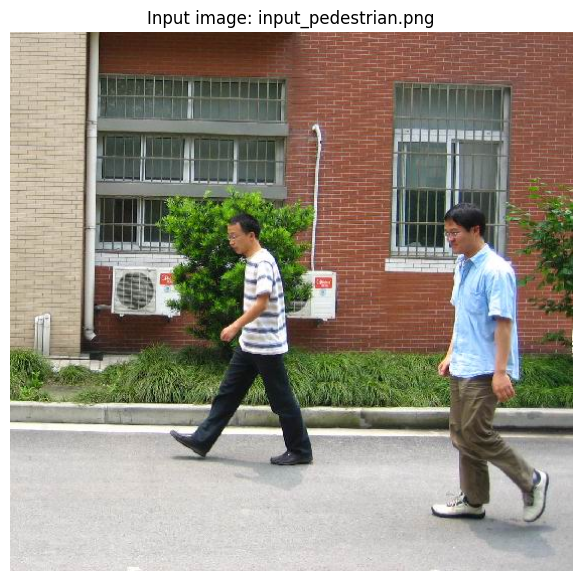

In [4]:
# Display the supplied input image.
input_image = Image.open('input_pedestrian.png').convert('RGB')
plt.figure(figsize=(8, 7))
plt.imshow(input_image)
plt.title('Input image: input_pedestrian.png')
plt.axis('off')
plt.show()

## 2. Dataset class and preprocessing

Each non-zero value in a mask represents one object instance. The minimum and maximum x/y locations of each instance form its ground-truth bounding box. Label `0` is reserved for background and label `1` represents a pedestrian.

In [5]:
class PennFudanDataset(Dataset):
    def __init__(self, root, train=True):
        self.root = Path(root)
        self.train = train
        self.images = sorted((self.root / 'PNGImages').glob('*.png'))
        self.masks = sorted((self.root / 'PedMasks').glob('*.png'))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = Image.open(self.images[index]).convert('RGB')
        mask = np.array(Image.open(self.masks[index]))

        object_ids = np.unique(mask)
        object_ids = object_ids[object_ids != 0]
        instance_masks = mask == object_ids[:, None, None]

        boxes = []
        valid_masks = []
        for instance_mask in instance_masks:
            ys, xs = np.where(instance_mask)
            if len(xs) == 0 or len(ys) == 0:
                continue
            xmin, xmax = xs.min(), xs.max()
            ymin, ymax = ys.min(), ys.max()
            if xmax > xmin and ymax > ymin:
                boxes.append([xmin, ymin, xmax, ymax])
                valid_masks.append(instance_mask)

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.ones((len(boxes),), dtype=torch.int64)
        masks = torch.as_tensor(np.asarray(valid_masks), dtype=torch.uint8)
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        iscrowd = torch.zeros((len(boxes),), dtype=torch.int64)

        target = {
            'boxes': boxes,
            'labels': labels,
            'masks': masks,
            'image_id': torch.tensor([index]),
            'area': area,
            'iscrowd': iscrowd,
        }

        image = F.pil_to_tensor(image).float() / 255.0
        if self.train and random.random() < 0.5:
            image = F.hflip(image)
            width = image.shape[-1]
            boxes = target['boxes'].clone()
            boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
            target['boxes'] = boxes
            target['masks'] = torch.flip(target['masks'], dims=[2])
        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

full_dataset = PennFudanDataset(ROOT, train=True)
indices = torch.randperm(len(full_dataset), generator=torch.Generator().manual_seed(SEED)).tolist()
train_indices, test_indices = indices[:-30], indices[-30:]
train_set = Subset(full_dataset, train_indices)

# Disable random augmentation for validation.
test_dataset = PennFudanDataset(ROOT, train=False)
test_set = Subset(test_dataset, test_indices)

train_loader = DataLoader(train_set, batch_size=2, shuffle=True, num_workers=2,
                          collate_fn=collate_fn, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_set, batch_size=1, shuffle=False, num_workers=2,
                         collate_fn=collate_fn)
print('Training images:', len(train_set))
print('Testing images:', len(test_set))

Training images: 140
Testing images: 30


## 3. Visualize ground-truth boxes

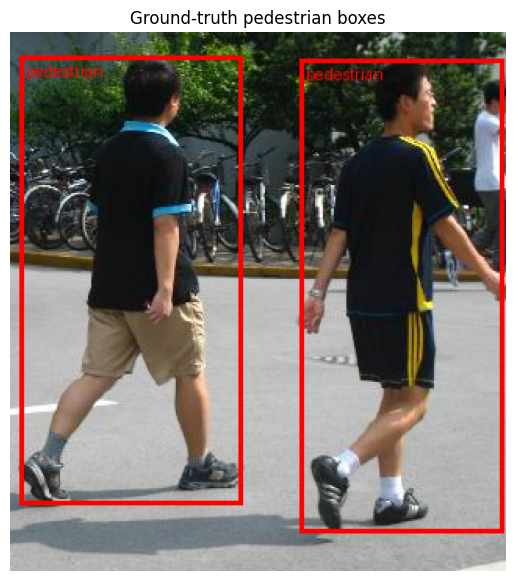

In [6]:
image, target = test_set[0]
visual = draw_bounding_boxes(
    (image * 255).to(torch.uint8),
    target['boxes'],
    labels=['pedestrian'] * len(target['boxes']),
    colors='red', width=3
)
plt.figure(figsize=(9, 7))
plt.imshow(visual.permute(1, 2, 0))
plt.title('Ground-truth pedestrian boxes')
plt.axis('off')
plt.show()

## 4. Build Faster R-CNN

A COCO-pretrained Faster R-CNN ResNet-50 FPN model is loaded. Its final classifier is replaced with a two-class head: background and pedestrian.

In [7]:
import os
from pathlib import Path

# Create a writable PyTorch cache directory
TORCH_HOME = Path.cwd() / "torch_cache"
TORCH_HOME.mkdir(parents=True, exist_ok=True)

os.environ["TORCH_HOME"] = str(TORCH_HOME)

print("PyTorch cache:", TORCH_HOME.resolve())

PyTorch cache: /content/torch_cache


In [8]:
def create_model(num_classes=2):
    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT

    model = fasterrcnn_resnet50_fpn(weights=weights)

    in_features = model.roi_heads.box_predictor.cls_score.in_features

    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features, num_classes
    )

    return model


model = create_model(num_classes=2).to(device)

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=3, gamma=0.1
)

print("Model created successfully.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /content/torch_cache/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:03<00:00, 53.2MB/s]


Model created successfully.


## 5. Training

Five epochs are appropriate for a lab demonstration with transfer learning. On CPU this can be slow, so GPU runtime is strongly recommended.

Epoch 1 | step 20/70 | loss 0.4484
Epoch 1 | step 40/70 | loss 0.3204
Epoch 1 | step 60/70 | loss 0.2595
Epoch 1 | step 70/70 | loss 0.2428
Epoch 1 finished: avg loss=0.2428, time=41.1s
Epoch 2 | step 20/70 | loss 0.1369
Epoch 2 | step 40/70 | loss 0.1299
Epoch 2 | step 60/70 | loss 0.1267
Epoch 2 | step 70/70 | loss 0.1240
Epoch 2 finished: avg loss=0.1240, time=39.3s
Epoch 3 | step 20/70 | loss 0.0931
Epoch 3 | step 40/70 | loss 0.0995
Epoch 3 | step 60/70 | loss 0.1037
Epoch 3 | step 70/70 | loss 0.1050
Epoch 3 finished: avg loss=0.1050, time=38.4s
Epoch 4 | step 20/70 | loss 0.0739
Epoch 4 | step 40/70 | loss 0.0754
Epoch 4 | step 60/70 | loss 0.0755
Epoch 4 | step 70/70 | loss 0.0782
Epoch 4 finished: avg loss=0.0782, time=38.7s
Epoch 5 | step 20/70 | loss 0.0740
Epoch 5 | step 40/70 | loss 0.0760
Epoch 5 | step 60/70 | loss 0.0713
Epoch 5 | step 70/70 | loss 0.0711
Epoch 5 finished: avg loss=0.0711, time=38.7s


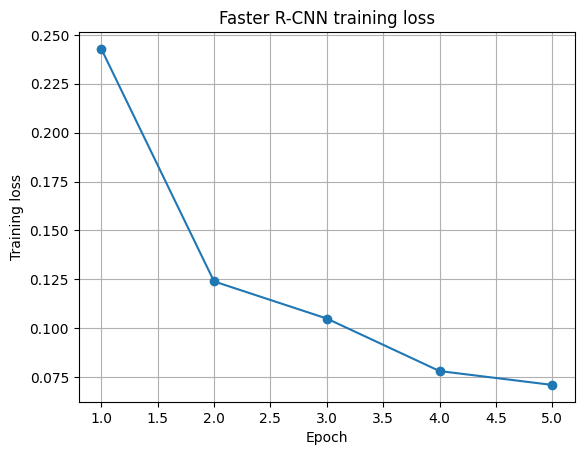

Saved model: faster_rcnn_pennfudan.pth


In [9]:
def train_one_epoch(model, loader, optimizer, device, epoch, print_freq=20):
    model.train()
    running = 0.0
    start = time.time()
    for step, (images, targets) in enumerate(loader, 1):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss: {loss.item()}')

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item()

        if step % print_freq == 0 or step == len(loader):
            print(f'Epoch {epoch} | step {step}/{len(loader)} | loss {running/step:.4f}')
    return running / len(loader), time.time() - start

EPOCHS = 5
history = []
for epoch in range(1, EPOCHS + 1):
    avg_loss, seconds = train_one_epoch(model, train_loader, optimizer, device, epoch)
    lr_scheduler.step()
    history.append(avg_loss)
    print(f'Epoch {epoch} finished: avg loss={avg_loss:.4f}, time={seconds:.1f}s')

plt.plot(range(1, EPOCHS + 1), history, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.title('Faster R-CNN training loss')
plt.grid(True); plt.show()

torch.save(model.state_dict(), 'faster_rcnn_pennfudan.pth')
print('Saved model: faster_rcnn_pennfudan.pth')

## 6. IoU-based evaluation

A predicted box is counted as correct when the confidence is at least `0.50` and its Intersection over Union with an unmatched ground-truth box is at least `0.50`. This provides understandable lab metrics: precision, recall, and F1-score.

In [10]:
from torchvision.ops import box_iou

@torch.no_grad()
def evaluate_detector(model, loader, device, score_threshold=0.50, iou_threshold=0.50):
    model.eval()
    tp = fp = fn = 0
    for images, targets in loader:
        images_device = [img.to(device) for img in images]
        outputs = model(images_device)
        for output, target in zip(outputs, targets):
            keep = output['scores'].cpu() >= score_threshold
            pred_boxes = output['boxes'].cpu()[keep]
            gt_boxes = target['boxes'].cpu()
            matched_gt = set()

            if len(pred_boxes) and len(gt_boxes):
                ious = box_iou(pred_boxes, gt_boxes)
                for pred_idx in range(len(pred_boxes)):
                    best_iou, gt_idx = ious[pred_idx].max(dim=0)
                    gt_idx = int(gt_idx)
                    if best_iou >= iou_threshold and gt_idx not in matched_gt:
                        tp += 1
                        matched_gt.add(gt_idx)
                    else:
                        fp += 1
                fn += len(gt_boxes) - len(matched_gt)
            else:
                fp += len(pred_boxes)
                fn += len(gt_boxes)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {'TP': tp, 'FP': fp, 'FN': fn,
            'precision': precision, 'recall': recall, 'F1': f1}

metrics = evaluate_detector(model, test_loader, device)
print(metrics)

{'TP': 64, 'FP': 12, 'FN': 0, 'precision': 0.8421052631578947, 'recall': 1.0, 'F1': 0.9142857142857143}


## 7. Inference on the supplied input image

The input file is `input_pedestrian.png`. The final image is saved as `rcnn_detection_output.png`.

/usr/local/lib/python3.13/dist-packages/torchvision/utils.py:375: UserWarning: Argument 'font_size' will be ignored since 'font' is not set.
  warnings.warn("Argument 'font_size' will be ignored since 'font' is not set.")


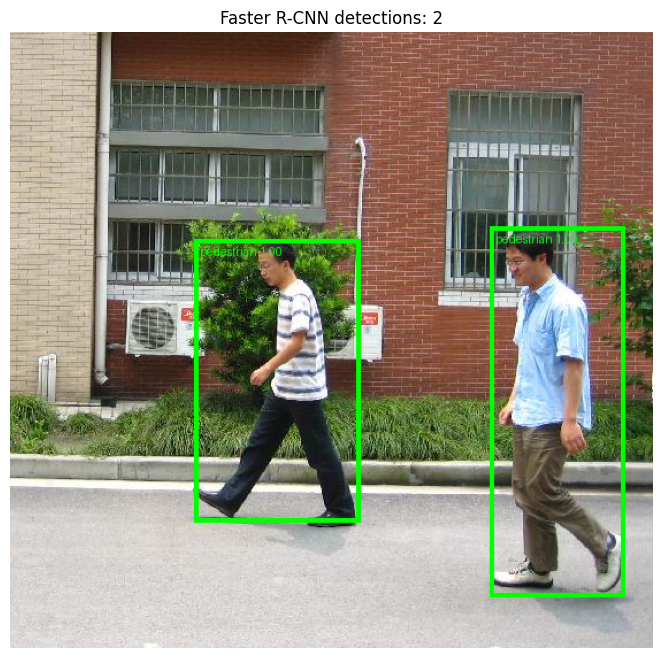

Saved output: rcnn_detection_output.png


In [11]:
@torch.no_grad()
def detect_and_draw(model, image_path, device, threshold=0.60):
    pil_image = Image.open(image_path).convert('RGB')
    tensor = F.pil_to_tensor(pil_image).float() / 255.0
    model.eval()
    prediction = model([tensor.to(device)])[0]

    keep = prediction['scores'].detach().cpu() >= threshold
    boxes = prediction['boxes'].detach().cpu()[keep]
    scores = prediction['scores'].detach().cpu()[keep]
    labels = [f'pedestrian {score:.2f}' for score in scores.tolist()]

    result = draw_bounding_boxes(
        F.pil_to_tensor(pil_image), boxes,
        labels=labels, colors='lime', width=4,
        font_size=18
    )
    output = F.to_pil_image(result)
    output.save('rcnn_detection_output.png')
    return output, len(boxes)

output_image, count = detect_and_draw(model, 'input_pedestrian.png', device)
plt.figure(figsize=(10, 8))
plt.imshow(output_image)
plt.title(f'Faster R-CNN detections: {count}')
plt.axis('off')
plt.show()
print('Saved output: rcnn_detection_output.png')

## Conclusion

Faster R-CNN combines a Region Proposal Network with ROI-based classification and bounding-box regression. Transfer learning allows the COCO-pretrained detector to be adapted to the Penn-Fudan pedestrian class with a comparatively small dataset. The final output localizes pedestrians using confidence-scored bounding boxes.

### Submission files produced by this notebook
- `input_pedestrian.png`: supplied test input image
- `faster_rcnn_pennfudan.pth`: trained model weights
- `rcnn_detection_output.png`: final detection result

If Colab disconnects before training finishes, reduce `EPOCHS` to 2 for a quick run. Keep 5 epochs for the final lab output when a GPU is available.